# Notebook 2 — Regresión reproducible sobre Airfoil Self-Noise (Problema 6)

**Objetivo:** predecir `sonido` (dB) a partir de `frecuencia`, `angulo`, `cuerda`, `velocidad` y `espesor`
(los nombres del notebook de clase). Los modelos entrenables son mis clases `OLSRegression`, `RidgeRegression`
y `LassoRegression` de `mlcore.py`.

Fuente: UCI ML Repository, *Airfoil Self-Noise* (Brooks, Pope y Marcolini, 1989), DOI 10.24432/C5VW2C,
licencia CC BY 4.0. Misma descarga que el notebook de clase.

**Autor:** Juan José Jiménez Maya.

In [1]:
import sys
import json
import time
import hashlib
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler

from mlcore import OLSRegression, RidgeRegression, LassoRegression

SEED = 2026
RES = Path("resultados")
RES.mkdir(exist_ok=True)
DATA = Path("data")
DATA.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.14.7
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1


In [2]:
# Si el archivo no está en data/, lo descargo de UCI (código de descarga del notebook de clase)
RAW = DATA / "airfoil_self_noise.dat"
if not RAW.exists():
    url = "https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip"
    with urlopen(url, timeout=60) as r:
        with ZipFile(BytesIO(r.read())) as z:
            nombre = [n for n in z.namelist() if Path(n).name == RAW.name][0]
            RAW.write_bytes(z.read(nombre))
sha = hashlib.sha256(RAW.read_bytes()).hexdigest()
print(f"Archivo: {RAW} | SHA-256: {sha}")

COLS = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor", "sonido"]
FEATURES = COLS[:-1]
df_raw = pd.read_csv(RAW, sep=r"\s+", header=None, names=COLS)
# id estable: número de línea en el archivo original (AF0001, AF0002, ...)
df_raw.insert(0, "id", [f"AF{i:04d}" for i in range(1, len(df_raw) + 1)])
df_raw = df_raw.set_index("id")
display(df_raw.head())

Archivo: data\airfoil_self_noise.dat | SHA-256: 74c75fd71783f1e6b71f8a622b993dc592897a97cd689c5090a07147a1b097b3


,frecuencia,angulo,cuerda,velocidad,espesor,sonido
id,,,,,,
AF0001,800,0.0,0.3048,71.3,0.0027,126.201
AF0002,1000,0.0,0.3048,71.3,0.0027,125.201
AF0003,1250,0.0,0.3048,71.3,0.0027,125.951
AF0004,1600,0.0,0.3048,71.3,0.0027,127.591
AF0005,2000,0.0,0.3048,71.3,0.0027,127.461


## 6a — Auditoría de formato, identidad y dominios (base completa, sin estadísticas aprendidas)

Unidades (documentación de UCI): frecuencia en Hz, ángulo de ataque en grados, cuerda en m, velocidad en m/s,
espesor de desplazamiento en m y sonido en dB. Solo reviso **reglas fijas** (positividad, ángulo no negativo,
tipos, ids, duplicados). No calculo cuantiles, imputaciones ni transformaciones con toda la base.

In [3]:
reglas = {
    "frecuencia > 0 (Hz)": df_raw.frecuencia > 0,
    "angulo >= 0 (grados)": df_raw.angulo >= 0,
    "cuerda > 0 (m)": df_raw.cuerda > 0,
    "velocidad > 0 (m/s)": df_raw.velocidad > 0,
    "espesor > 0 (m)": df_raw.espesor > 0,
    "sonido > 0 (dB)": df_raw.sonido > 0,
}
auditoria = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str), "faltantes": df_raw.isna().sum(),
    "valores únicos": df_raw.nunique(), "mín": df_raw.min(), "máx": df_raw.max(),
})
display(auditoria)
dup_completo = df_raw.duplicated(keep=False)
dup_predictores = df_raw[FEATURES].duplicated(keep=False)
nombres_reglas = list(reglas) + ["ids únicos", "filas duplicadas exactas", "filas con predictores repetidos"]
conteos = [int((~v).sum()) for v in reglas.values()]
conteos += [int(df_raw.index.duplicated().sum()), int(dup_completo.sum()), int(dup_predictores.sum())]
checks = pd.DataFrame({"regla": nombres_reglas, "filas que violan / casos": conteos})
display(checks)
auditoria.to_csv(RES / "p6_auditoria_columnas.csv")
checks.to_csv(RES / "p6_auditoria_reglas.csv", index=False)
df = df_raw.copy()           # ninguna regla elimina filas; df_raw queda intacto
assert all(v.all() for v in reglas.values()) and not dup_completo.any()

,dtype,faltantes,valores únicos,mín,máx
frecuencia,int64,0,21,200.0000,20000.0000
angulo,float64,0,27,0.0000,22.2000
cuerda,float64,0,6,0.0254,0.3048
velocidad,float64,0,4,31.7000,71.3000
espesor,float64,0,105,0.0004,0.0584
sonido,float64,0,1456,103.3800,140.9870


,regla,filas que violan / casos
0,frecuencia > 0 (Hz),0
1,angulo >= 0 (grados),0
2,cuerda > 0 (m),0
3,velocidad > 0 (m/s),0
4,espesor > 0 (m),0
5,sonido > 0 (dB),0
6,ids únicos,0
7,filas duplicadas exactas,0
8,filas con predictores repetidos,0


No hay faltantes, valores fuera de dominio ni duplicados. Aun así parto **por grupos de filas idénticas**: si hubiera
duplicados exactos quedarían del mismo lado. Como hay 0 duplicados, esto es igual a partir por filas.

In [4]:
# cada fila recibe un "grupo" = hash de sus valores; filas idénticas tendrían el mismo grupo
texto_fila = df.astype(str).agg("|".join, axis=1)
grupo = texto_fila.map(lambda s: hashlib.md5(s.encode()).hexdigest())
grupos = grupo.unique()
g_dev, g_test = train_test_split(grupos, test_size=0.2, random_state=SEED, shuffle=True)
particion = pd.Series(np.where(grupo.isin(set(g_test)), "prueba", "desarrollo"), index=df.index, name="particion")
manifiesto = pd.DataFrame({"particion": particion, "grupo_duplicado": grupo})
manifiesto.to_csv(RES / "p6_particiones.csv")
dev = df[particion == "desarrollo"].copy()
test = df[particion == "prueba"].copy()
assert set(dev.index).isdisjoint(test.index) and len(dev) + len(test) == len(df)
assert manifiesto.groupby("grupo_duplicado").particion.nunique().max() == 1
display(manifiesto.particion.value_counts().to_frame("filas"))
# Desde aquí no vuelvo a mirar `test` hasta la sección 6c.

,filas
particion,
desarrollo,1202
prueba,301


## EDA en desarrollo (80 %)

Hipótesis que planteé antes de mirar las gráficas:

* **H1.** El sonido baja con la frecuencia de forma no lineal; en escala logarítmica la relación sería más lineal.
* **H2.** El espesor depende mucho del ángulo y es muy asimétrico; en un modelo lineal pueden "pisarse" (redundancia).
* **H3.** A mayor velocidad, más sonido; las diferencias por grupo hay que leerlas con el tamaño de cada grupo.

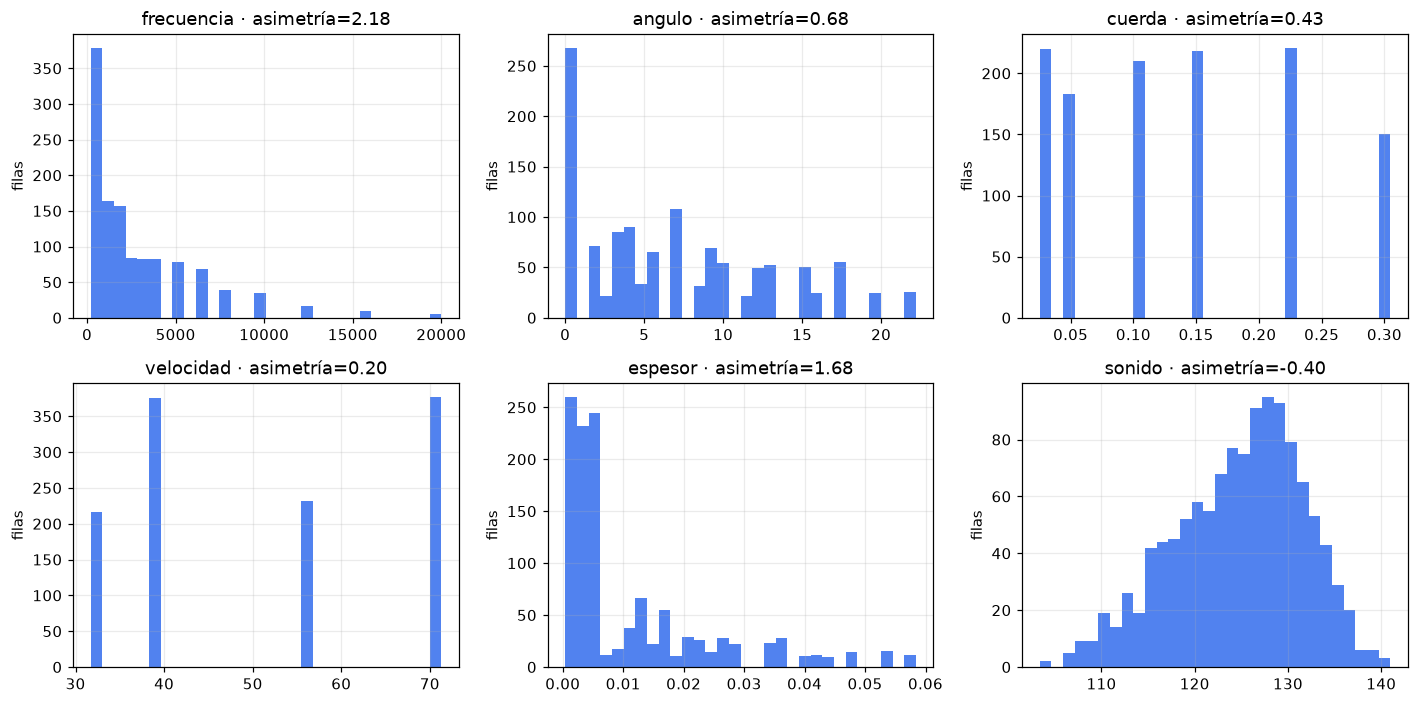

,count,mean,std,min,25%,50%,75%,max,asimetría,valores únicos
frecuencia,1202.0,2846.7304,3117.3616,200.0000,800.0000,1600.0000,4000.0000,20000.0000,2.1804,21
angulo,1202.0,6.8543,6.0177,0.0000,2.0000,5.4000,11.2000,22.2000,0.6815,27
cuerda,1202.0,0.1378,0.0935,0.0254,0.0508,0.1016,0.2286,0.3048,0.4296,6
velocidad,1202.0,51.1852,15.5314,31.7000,39.6000,55.5000,71.3000,71.3000,0.1997,4
espesor,1202.0,0.0113,0.0132,0.0004,0.0025,0.0050,0.0161,0.0584,1.6773,105
sonido,1202.0,124.7642,6.8904,103.3800,120.0800,125.7225,129.8662,140.9870,-0.3997,1171


In [5]:
# Análisis univariado: histogramas
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), COLS):
    ax.hist(dev[c], bins=30, color="#2563eb", alpha=0.8)
    ax.set(title=f"{c} · asimetría={dev[c].skew():.2f}", ylabel="filas")
plt.tight_layout()
plt.savefig(RES / "p6_univariado.png", bbox_inches="tight")
plt.show()
uni = dev.describe().T
uni["asimetría"] = dev.skew()
uni["valores únicos"] = dev.nunique()
display(uni)

,pearson con sonido,spearman con sonido,pearson log10(x) con sonido
variable,,,
frecuencia,-0.3900,-0.3488,-0.3610
angulo,-0.1620,-0.1530,NaN
cuerda,-0.2387,-0.2438,-0.2353
velocidad,0.1270,0.1144,0.1242
espesor,-0.3177,-0.2938,-0.3265


,frecuencia,angulo,cuerda,velocidad,espesor
frecuencia,1.000,-0.281,-0.006,0.107,-0.336
angulo,-0.281,1.000,-0.483,0.049,0.885
cuerda,-0.006,-0.483,1.000,-0.007,-0.103
velocidad,0.107,0.049,-0.007,1.000,-0.033
espesor,-0.336,0.885,-0.103,-0.033,1.000


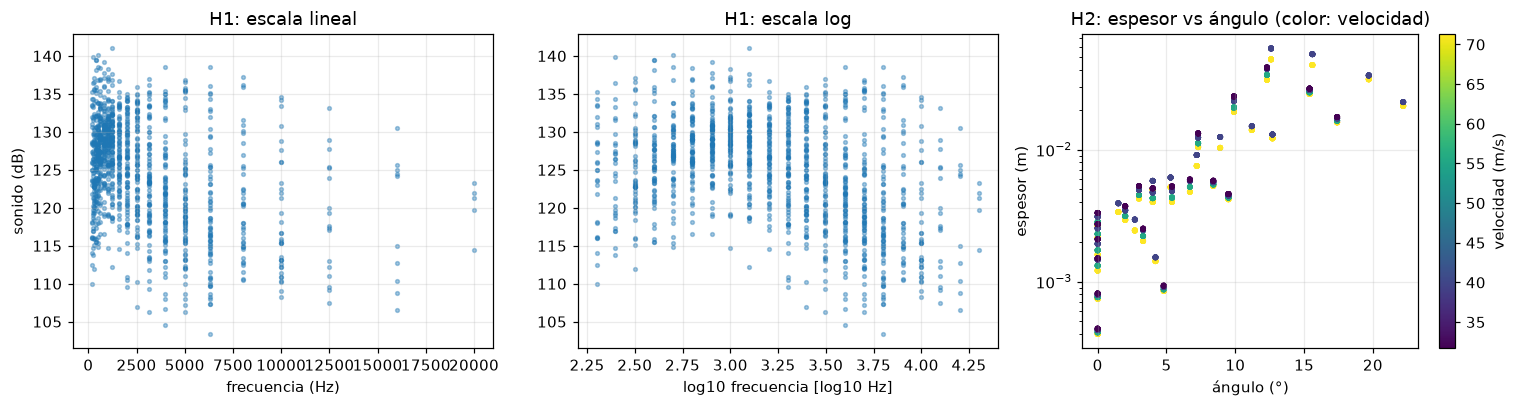

frecuencia,200,250,315,400,500,630,800,1000,1250,1600,...,2500,3150,4000,5000,6300,8000,10000,12500,16000,20000
n,27.00,29.00,50.00,56.00,61.00,74.00,82.00,81.00,83.00,75.00,...,84.00,82.0,83.00,78.00,69.00,39.00,35.00,17.00,10.00,5.00
media,124.35,124.99,125.25,126.32,126.96,128.11,128.56,128.68,127.95,126.87,...,125.26,123.4,121.66,120.67,119.17,120.76,118.27,118.73,118.31,120.12


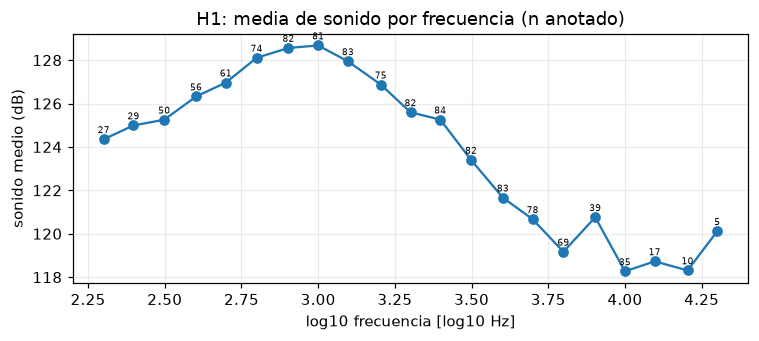

In [6]:
# Análisis de asociación: correlaciones con el sonido
asoc = []
for c in FEATURES:
    fila = {"variable": c,
            "pearson con sonido": stats.pearsonr(dev[c], dev.sonido).statistic,
            "spearman con sonido": stats.spearmanr(dev[c], dev.sonido).statistic}
    if (dev[c] > 0).all():
        fila["pearson log10(x) con sonido"] = stats.pearsonr(np.log10(dev[c]), dev.sonido).statistic
    else:
        fila["pearson log10(x) con sonido"] = np.nan
    asoc.append(fila)
asoc = pd.DataFrame(asoc).set_index("variable")
display(asoc)
display(dev[FEATURES].corr(method="spearman").round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].scatter(dev.frecuencia, dev.sonido, s=6, alpha=0.4)
axes[0].set(xlabel="frecuencia (Hz)", ylabel="sonido (dB)", title="H1: escala lineal")
axes[1].scatter(np.log10(dev.frecuencia), dev.sonido, s=6, alpha=0.4)
axes[1].set(xlabel="log10 frecuencia [log10 Hz]", title="H1: escala log")
sc = axes[2].scatter(dev.angulo, dev.espesor, c=dev.velocidad, s=8, cmap="viridis")
axes[2].set(xlabel="ángulo (°)", ylabel="espesor (m)", yscale="log", title="H2: espesor vs ángulo (color: velocidad)")
plt.colorbar(sc, ax=axes[2], label="velocidad (m/s)")
plt.tight_layout()
plt.savefig(RES / "p6_asociacion.png", bbox_inches="tight")
plt.show()

# media del sonido en cada una de las 21 frecuencias (con su n)
por_frecuencia = dev.groupby("frecuencia").sonido.agg(n="size", media="mean")
display(por_frecuencia.T.round(2))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(np.log10(por_frecuencia.index), por_frecuencia.media, "o-")
for f, r in por_frecuencia.iterrows():
    ax.annotate(str(int(r.n)), (np.log10(f), r.media), fontsize=6, xytext=(0, 4),
                textcoords="offset points", ha="center")
ax.set(xlabel="log10 frecuencia [log10 Hz]", ylabel="sonido medio (dB)", title="H1: media de sonido por frecuencia (n anotado)")
plt.tight_layout()
plt.savefig(RES / "p6_sonido_por_frecuencia.png", bbox_inches="tight")
plt.show()

,n,media,mediana,desv
velocidad,,,,
31.7,217,124.2620,124.8380,6.6558
39.6,376,123.5497,124.6345,7.0316
55.5,232,125.4375,126.1595,6.2223
71.3,377,125.8503,126.7460,7.0727


,n,media,mediana,desv
cuerda,,,,
0.0254,220,126.9981,126.8720,6.3480
0.0508,183,126.1631,127.0760,6.0095
0.1016,210,126.1054,127.7655,7.7415
0.1524,218,122.9524,124.2800,7.2798
0.2286,221,123.8872,124.0860,5.9728
0.3048,150,121.8289,123.0935,6.2054


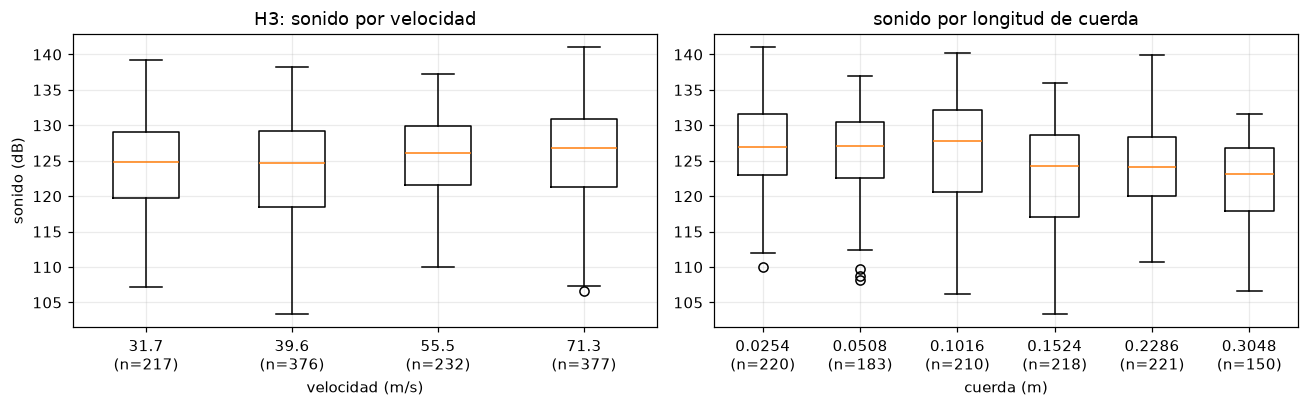

,n,pendiente sonido~log10 f
velocidad,,
31.7,217,-4.4002
39.6,376,-5.7995
55.5,232,-4.5351
71.3,377,-6.7630


In [7]:
# Análisis por grupos: velocidad y cuerda (con tamaño de grupo)
por_velocidad = dev.groupby("velocidad").sonido.agg(n="size", media="mean", mediana="median", desv="std")
por_cuerda = dev.groupby("cuerda").sonido.agg(n="size", media="mean", mediana="median", desv="std")
display(por_velocidad)
display(por_cuerda)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].boxplot([dev.sonido[dev.velocidad == v] for v in por_velocidad.index],
                tick_labels=[f"{v}\n(n={n})" for v, n in por_velocidad.n.items()])
axes[0].set(xlabel="velocidad (m/s)", ylabel="sonido (dB)", title="H3: sonido por velocidad")
axes[1].boxplot([dev.sonido[dev.cuerda == v] for v in por_cuerda.index],
                tick_labels=[f"{v:.4f}\n(n={n})" for v, n in por_cuerda.n.items()])
axes[1].set(xlabel="cuerda (m)", title="sonido por longitud de cuerda")
plt.tight_layout()
plt.savefig(RES / "p6_grupos.png", bbox_inches="tight")
plt.show()

# pendiente de sonido contra log10(frecuencia) dentro de cada velocidad
pendientes = []
for v, g in dev.groupby("velocidad"):
    pendiente = np.polyfit(np.log10(g.frecuencia), g.sonido, 1)[0]
    pendientes.append({"velocidad": v, "n": len(g), "pendiente sonido~log10 f": pendiente})
display(pd.DataFrame(pendientes).set_index("velocidad"))

In [8]:
# Valores fuera de los bigotes (regla 1.5 IQR): solo para mirar, NO se eliminan
fuera_bigotes = {}
for c in COLS:
    q1, q3 = dev[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera_bigotes[c] = int(((dev[c] < q1 - 1.5 * iqr) | (dev[c] > q3 + 1.5 * iqr)).sum())
print("Filas fuera de los bigotes (solo diagnóstico, no se eliminan):", fuera_bigotes)

Filas fuera de los bigotes (solo diagnóstico, no se eliminan): {'frecuencia': 67, 'angulo': 0, 'cuerda': 0, 'velocidad': 0, 'espesor': 102, 'sonido': 2}


### Registro del EDA (solo desarrollo, n = 1202)

| # | Hallazgo | Evidencia | Decisión | Riesgo de fuga |
|---|---|---|---|---|
| H1 | La relación sonido–frecuencia **no** es monótona ni más lineal en log: tiene forma de U invertida con el máximo cerca de 0.8–1 kHz. H1 se rechaza en parte. | Pearson con $f$: −0.390; con $\log_{10}f$: −0.361. Medias: 124.4 dB (200 Hz) → 128.7 dB (1 kHz) → 118.3 dB (10 kHz). | Representación B: $\log_{10}f$ y $(\log_{10}f-3)^2$ con centro fijo. | Ninguno: son transformaciones fijas. |
| H2 | Espesor y ángulo están muy asociados (Spearman 0.885) y el espesor es asimétrico (1.68). Tomar log del espesor casi no cambia su relación con el sonido. | Matriz de Spearman; dispersión espesor vs ángulo. | Dejo las dos variables y comparo con Ridge/Lasso; no transformo el espesor. | Ninguno. |
| H3 | Más velocidad → sonido medio algo mayor, pero el efecto es pequeño. | Medias 124.3 / 123.5 / 125.4 / 125.9 dB para 31.7 / 39.6 / 55.5 / 71.3 m/s con n = 217 / 376 / 232 / 377. La pendiente frente a $\log_{10}f$ cambia entre velocidades (−4.4 a −6.8 dB/década). | Velocidad queda lineal; las interacciones quedan como limitación. | Ninguno. |
| — | Fuera de bigotes: frecuencia 67, espesor 102, sonido 2. Son parte del diseño del experimento, no errores. | Regla IQR solo para mirar. | **No elimino filas.** | Eliminar con cuantiles de toda la base sería fuga. |

## 6b — Validación cruzada de 5 pliegues en desarrollo

**Representaciones** (decididas después del EDA y antes de la CV):

* **A — originales:** las cinco variables, estandarizadas dentro de cada pliegue.
* **B — alternativa (2 transformaciones, por H1):** cambio `frecuencia` por `log10_frecuencia` $=\log_{10}(f/1\,\text{Hz})$
  y `log10_frecuencia_c2` $=(\log_{10}(f/1\,\text{Hz})-3)^2$. Dominio: $f>0$ Hz; unidades: $\log_{10}$Hz y $(\log_{10}\text{Hz})^2$.
  El 3 (=1000 Hz) es una constante que elegí yo, **no** se calcula con los datos. El cuadrado permite la U invertida.
  El modelo sigue siendo lineal en sus parámetros.

**Grilla** (la del problema 5, fijada antes de comparar): $\{10^{-3},10^{-2},10^{-1},1,10\}$.

**Criterio y desempate fijados antes:** gana el menor RMSE medio en los 5 pliegues. Si dos candidatos quedan a menos de
0.001 dB, prefiero: (1) representación A, (2) mayor λ, (3) Ridge antes que Lasso. Pliegues:
`KFold(5, shuffle=True, random_state=2026)`, los mismos para todos.

In [9]:
def representacion(datos, rep):
    X = datos[FEATURES].copy()
    if rep == "B":
        lf = np.log10(X.pop("frecuencia"))
        X.insert(0, "log10_frecuencia", lf)
        X.insert(1, "log10_frecuencia_c2", (lf - 3.0) ** 2)   # centro fijo en 1000 Hz
    return X


def crear_modelo(nombre, lam):
    if nombre == "OLS":
        return OLSRegression()
    if nombre == "Ridge":
        return RidgeRegression(lam2=lam)
    return LassoRegression(lam1=lam, accelerate=True, tol=1e-8, max_iter=200_000)


def ajustar_predecir(nombre, lam, rep, datos_ajuste, datos_eval):
    """Ajusta el escalador y el modelo SOLO con datos_ajuste y predice datos_eval."""
    Xf = representacion(datos_ajuste, rep)
    Xe = representacion(datos_eval, rep)
    yf = datos_ajuste.sonido.to_numpy()
    if nombre == "Media":
        return np.full(len(datos_eval), yf.mean()), None
    if nombre == "Mediana":
        return np.full(len(datos_eval), np.median(yf)), None
    escalador = StandardScaler().fit(Xf)
    m = crear_modelo(nombre, lam).fit(escalador.transform(Xf), yf)
    return m.predict(escalador.transform(Xe)), (m, escalador, list(Xf.columns))


def metricas(y, p):
    e = y - p
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e))),
            "R2": float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2))}


LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
candidatos = [("Media", None, "A"), ("Mediana", None, "A")]
for rep in ["A", "B"]:
    candidatos.append(("OLS", None, rep))
    for modelo in ["Ridge", "Lasso"]:
        for lam in LAMBDAS:
            candidatos.append((modelo, lam, rep))

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
pliegues = list(kf.split(dev))
filas_pliegues = []
for k, (_, i_eval) in enumerate(pliegues):
    for i in i_eval:
        filas_pliegues.append({"id": dev.index[i], "pliegue_validacion": k + 1})
pd.DataFrame(filas_pliegues).to_csv(RES / "p6_pliegues_cv.csv", index=False)

filas = []
for nombre, lam, rep in candidatos:
    for k, (i_ajuste, i_eval) in enumerate(pliegues, 1):
        p, info = ajustar_predecir(nombre, lam, rep, dev.iloc[i_ajuste], dev.iloc[i_eval])
        fila = {"modelo": nombre, "lambda": lam, "rep": rep, "pliegue": k,
                **metricas(dev.sonido.iloc[i_eval].to_numpy(), p)}
        if info is not None:
            fila["coef_no_nulos"] = int(np.sum(info[0].coef_ != 0))
        filas.append(fila)
cv = pd.DataFrame(filas)
cv.to_csv(RES / "p6_cv_por_pliegue.csv", index=False)
resumen = (cv.groupby(["modelo", "lambda", "rep"], dropna=False, sort=False)
             .agg(RMSE_media=("RMSE", "mean"), RMSE_sd=("RMSE", "std"), RMSE_min=("RMSE", "min"),
                  RMSE_max=("RMSE", "max"), MAE_media=("MAE", "mean"), R2_media=("R2", "mean"),
                  coef_no_nulos=("coef_no_nulos", "mean"))
             .reset_index())
resumen.to_csv(RES / "p6_cv_resumen.csv", index=False)
display(resumen.sort_values("RMSE_media"))

,modelo,lambda,rep,RMSE_media,RMSE_sd,RMSE_min,RMSE_max,MAE_media,R2_media,coef_no_nulos
15,Ridge,0.010,B,4.6111,0.1904,4.3560,4.8438,3.5274,0.5496,6.0
14,Ridge,0.001,B,4.6113,0.1925,4.3505,4.8411,3.5213,0.5496,6.0
13,OLS,NaN,B,4.6114,0.1928,4.3500,4.8408,3.5206,0.5496,6.0
19,Lasso,0.001,B,4.6115,0.1927,4.3502,4.8409,3.5209,0.5496,6.0
20,Lasso,0.010,B,4.6116,0.1920,4.3520,4.8414,3.5234,0.5495,6.0
21,Lasso,0.100,B,4.6223,0.1855,4.3794,4.8564,3.5561,0.5475,6.0
16,Ridge,0.100,B,4.6496,0.1845,4.4249,4.9021,3.6128,0.5421,6.0
3,Ridge,0.001,A,4.7780,0.2113,4.4382,4.9913,3.7080,0.5161,5.0
4,Ridge,0.010,A,4.7781,0.2060,4.4463,4.9797,3.7143,0.5161,5.0
8,Lasso,0.001,A,4.7781,0.2118,4.4376,4.9924,3.7076,0.5161,5.0


In [10]:
def seleccionar(tabla, tol=1e-3):
    """Aplica la regla: menor RMSE medio y, si hay empate (< tol), rep A, mayor lambda, Ridge."""
    t = tabla.copy()
    mejor = t.RMSE_media.min()
    empatados = t[t.RMSE_media - mejor < tol].copy()
    empatados["_rep"] = (empatados.rep != "A").astype(int)           # 0 si es A
    empatados["_lam"] = -empatados["lambda"].fillna(0)                # mayor lambda primero
    empatados["_mod"] = empatados.modelo.map({"Ridge": 0, "Lasso": 1, "OLS": 2})
    return empatados.sort_values(["_rep", "_lam", "_mod"]).iloc[0], empatados


regularizados = resumen[resumen.modelo.isin(["Ridge", "Lasso"])]
elegido_reg, empatados_reg = seleccionar(regularizados)
elegido_ols, _ = seleccionar(resumen[resumen.modelo == "OLS"])
seleccion = {
    "criterio": "menor RMSE medio en 5 pliegues; desempate <0.001 dB: rep A, mayor lambda, Ridge",
    "regularizado": {"modelo": elegido_reg.modelo, "lambda": float(elegido_reg["lambda"]), "rep": elegido_reg.rep,
                     "RMSE_media": float(elegido_reg.RMSE_media), "RMSE_sd": float(elegido_reg.RMSE_sd),
                     "candidatos_en_empate": int(len(empatados_reg))},
    "OLS": {"rep": elegido_ols.rep, "RMSE_media": float(elegido_ols.RMSE_media), "RMSE_sd": float(elegido_ols.RMSE_sd)},
    "referencia": "Media (MSE/RMSE) y Mediana (MAE) de desarrollo",
}
with open(RES / "p6_registro_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)
print(json.dumps(seleccion, indent=2, ensure_ascii=False))

{
  "criterio": "menor RMSE medio en 5 pliegues; desempate <0.001 dB: rep A, mayor lambda, Ridge",
  "regularizado": {
    "modelo": "Ridge",
    "lambda": 0.01,
    "rep": "B",
    "RMSE_media": 4.611113457234589,
    "RMSE_sd": 0.19038600138195708,
    "candidatos_en_empate": 4
  },
  "OLS": {
    "rep": "B",
    "RMSE_media": 4.611447604641201,
    "RMSE_sd": 0.19280303835451268
  },
  "referencia": "Media (MSE/RMSE) y Mediana (MAE) de desarrollo"
}


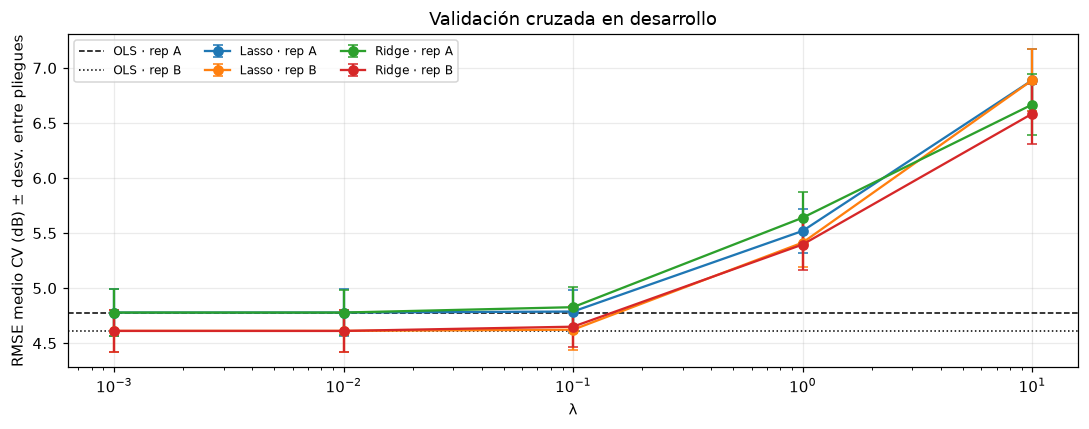

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for (modelo, rep), g in regularizados.groupby(["modelo", "rep"]):
    ax.errorbar(g["lambda"], g.RMSE_media, yerr=g.RMSE_sd, marker="o", capsize=3, label=f"{modelo} · rep {rep}")
for rep, estilo in [("A", "--"), ("B", ":")]:
    rmse_ols = resumen[(resumen.modelo == "OLS") & (resumen.rep == rep)].RMSE_media.iloc[0]
    ax.axhline(rmse_ols, color="k", ls=estilo, lw=1, label=f"OLS · rep {rep}")
ax.set(xscale="log", xlabel="λ", ylabel="RMSE medio CV (dB) ± desv. entre pliegues", title="Validación cruzada en desarrollo")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig(RES / "p6_cv.png", bbox_inches="tight")
plt.show()

**Interpretación de la CV.** La representación B baja el RMSE medio de ≈4.778 dB a ≈4.611 dB en todos los modelos poco
regularizados; la mejora (0.17 dB) es parecida a la desviación entre pliegues (≈0.19 dB) pero aparece en los cinco
pliegues. Dentro de cada representación, OLS, Ridge y Lasso con λ ≤ 0.01 empatan (< 0.001 dB): con ≈960 filas y 5–6
variables estandarizadas el problema está bien condicionado y no hay mucha varianza que corregir. Con λ ≥ 0.1 domina el
sesgo; con λ1 = 10, Lasso pone todo en cero y queda igual a la media. Con la regla fijada, el regularizado elegido es
**Ridge λ2 = 0.01, representación B** (4 candidatos empatados; gana mayor λ y Ridge). El finalista OLS también usa B.

## 6c — Evaluación final, una sola vez, en prueba
Representación e hiperparámetros congelados. Reajusto los finalistas con todo el desarrollo (escalador incluido) y
evalúo **una sola vez** en prueba. Segmentos definidos con desarrollo: frecuencia ≤ mediana de desarrollo vs. > mediana.

In [12]:
finalistas = {
    "Referencia (media / mediana)": ("Media", None, "A"),
    f"OLS · rep {elegido_ols.rep}": ("OLS", None, elegido_ols.rep),
    f"{elegido_reg.modelo} λ={elegido_reg['lambda']:g} · rep {elegido_reg.rep}":
        (elegido_reg.modelo, float(elegido_reg["lambda"]), elegido_reg.rep),
}
F_MED = float(dev.frecuencia.median())           # mediana calculada con desarrollo
seg_test = np.where(test.frecuencia <= F_MED, f"f ≤ {F_MED:.0f} Hz", f"f > {F_MED:.0f} Hz")
y_test = test.sonido.to_numpy()
pred_final = {}
filas = []
filas_seg = []
modelos_finales = {}
for etiqueta, (nombre, lam, rep) in finalistas.items():
    p, info = ajustar_predecir(nombre, lam, rep, dev, test)
    pred_final[etiqueta] = p
    met = metricas(y_test, p)
    if nombre == "Media":
        met["MAE"] = float(np.mean(np.abs(y_test - np.median(dev.sonido))))   # para MAE la referencia es la mediana
    filas.append({"modelo": etiqueta, **met})
    for s in np.unique(seg_test):
        msk = seg_test == s
        filas_seg.append({"modelo": etiqueta, "segmento": s, "n": int(msk.sum()),
                          "RMSE": float(np.sqrt(np.mean((y_test[msk] - p[msk]) ** 2))),
                          "sesgo medio (obs - pred)": float(np.mean(y_test[msk] - p[msk]))})
    if info is not None:
        modelos_finales[etiqueta] = info
final = pd.DataFrame(filas).set_index("modelo")
segmentos = pd.DataFrame(filas_seg)
final.to_csv(RES / "p6_evaluacion_final.csv")
segmentos.to_csv(RES / "p6_errores_por_segmento.csv", index=False)
display(final)
display(segmentos.pivot(index="modelo", columns="segmento"))
coefs = pd.DataFrame({k: pd.Series(m.coef_, index=cols) for k, (m, esc, cols) in modelos_finales.items()})
display(coefs.rename_axis("coeficiente (por desv. estándar de desarrollo)"))
predicciones = pd.DataFrame({"id": test.index, "sonido_observado": y_test})
for k, v in pred_final.items():
    predicciones[f"pred_{k}"] = v
predicciones.to_csv(RES / "p6_predicciones_prueba.csv", index=False)

,RMSE,MAE,R2
modelo,,,
Referencia (media / mediana),6.9332,5.6535,-0.0027
OLS · rep B,4.9238,3.6936,0.4943
Ridge λ=0.01 · rep B,4.9207,3.7001,0.4949


n                    RMSE             sesgo medio (obs - pred)            
segmento                     f > 1600 Hz f ≤ 1600 Hz f > 1600 Hz f ≤ 1600 Hz              f > 1600 Hz f ≤ 1600 Hz
modelo                                                                                                           
OLS · rep B                          152         149      3.8251      5.8352                   0.3308      0.2410
Referencia (media / mediana)         152         149      7.7687      5.9615                  -1.7865      2.5458
Ridge λ=0.01 · rep B                 152         149      3.8622      5.8050                   0.3141      0.2664

,OLS · rep B,Ridge λ=0.01 · rep B
coeficiente (por desv. estándar de desarrollo),,
log10_frecuencia,-2.3357,-2.3003
log10_frecuencia_c2,-2.2965,-2.2785
angulo,-2.6187,-2.5167
cuerda,-3.4385,-3.3587
velocidad,1.4655,1.4405
espesor,-1.9119,-1.9396


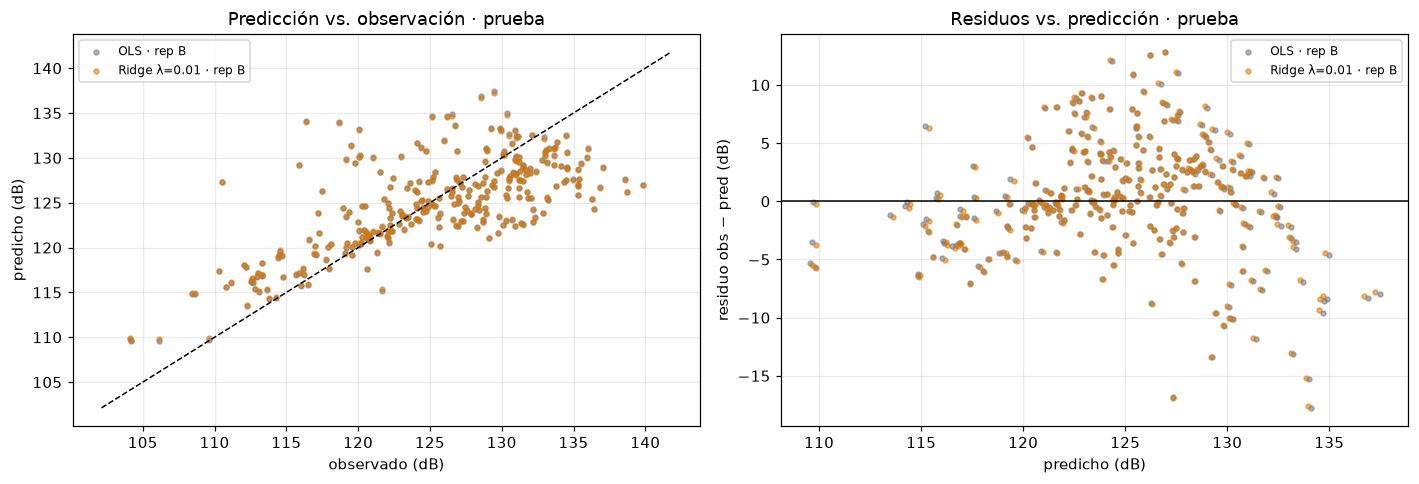

frecuencia,200,250,315,400,500,630,800,1000,1250,1600,...,2500,3150,4000,5000,6300,8000,10000,12500,16000,20000
n,8.00,13.00,6.00,13.00,17.0,14.00,15.00,18.00,17.00,28.00,...,20.00,21.00,19.00,17.00,20.0,13.00,7.00,8.00,3.00,1.00
residuo medio (dB),1.52,0.64,2.52,0.22,-2.3,-1.13,2.98,-0.17,0.68,0.11,...,-0.46,0.76,0.53,0.76,-0.4,1.45,-0.13,1.13,-0.23,-0.23


Tiempo total del notebook: 5.7 s


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
lims = [y_test.min() - 2, y_test.max() + 2]
for (et, p), c in zip(list(pred_final.items())[1:], ["#64748b", "#d97706"]):
    axes[0].scatter(y_test, p, s=10, alpha=0.55, color=c, label=et)
    axes[1].scatter(p, y_test - p, s=10, alpha=0.55, color=c, label=et)
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set(xlabel="observado (dB)", ylabel="predicho (dB)", title="Predicción vs. observación · prueba")
axes[1].axhline(0, color="k", lw=1)
axes[1].set(xlabel="predicho (dB)", ylabel="residuo obs − pred (dB)", title="Residuos vs. predicción · prueba")
for a in axes:
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RES / "p6_final.png", bbox_inches="tight")
plt.show()

# residuo medio por frecuencia (solo diagnóstico; no se reajusta nada)
et_reg = list(pred_final)[2]
res_f = pd.DataFrame({"frecuencia": test.frecuencia, "residuo": y_test - pred_final[et_reg]})
res_f = res_f.groupby("frecuencia").residuo.agg(["size", "mean"])
display(res_f.rename(columns={"size": "n", "mean": "residuo medio (dB)"}).T.round(2))
print(f"Tiempo total del notebook: {time.time() - T0:.1f} s")

**Interpretación de la evaluación final.** En prueba, OLS (B) y Ridge λ=0.01 (B) obtienen RMSE ≈ 4.92 dB,
MAE ≈ 3.70 dB y $R^2$ ≈ 0.49, frente a RMSE 6.93 dB de la referencia constante. La diferencia entre OLS y Ridge
(0.003 dB) no importa y es coherente con la CV. El RMSE de prueba es mayor que el de CV (4.61 dB) y que el peor pliegue
(4.84 dB): una sola partición de 301 filas tiene su propia variabilidad, y no uso esa diferencia para reajustar nada.

**Errores sistemáticos.** (i) La nube predicho vs. observado tiene pendiente menor que 1: se sobreestiman los sonidos
bajos y se subestiman los altos. (ii) El error es mucho mayor en frecuencias ≤ 1600 Hz (RMSE ≈ 5.8 dB) que en > 1600 Hz
(≈ 3.8 dB). Las dos cosas indican que faltan interacciones (por ejemplo frecuencia × espesor / velocidad, como el número
de Strouhal $f\cdot\delta/U$), que un modelo aditivo con solo dos transformaciones no captura.

## 6d — Escenario de generalización y elección del modelo

Una partición aleatoria de filas mide **interpolación dentro del mismo experimento**: las filas de prueba casi siempre
tienen otras frecuencias del mismo ensayo (misma cuerda, ángulo y velocidad) en desarrollo. Responde "¿qué tan bien
predigo otra frecuencia de un ensayo parecido a los que ya vi?".

Para medir **condiciones nuevas** habría que partir por grupos: por ejemplo `GroupKFold` agrupando por ensayo
(cuerda × ángulo × velocidad), para que todas las frecuencias de un ensayo queden del mismo lado; o guardar valores
completos (una velocidad o una cuerda nunca vista). No hice esa evaluación, así que **no** afirmo esa capacidad.

**OLS, Ridge o Lasso.** La evidencia (empates < 0.001 dB en CV, la misma diferencia en prueba, Lasso con λ1 ≤ 0.01 no
anula ningún coeficiente) dice que regularizar no ayuda aquí: elegí Ridge λ=0.01 solo por la regla de desempate, y OLS
sería igual de defendible. La mejora real viene de la representación B. Los coeficientes son asociaciones dentro de este
diseño experimental, no efectos causales.